<a href="https://colab.research.google.com/github/davidfwallace/metastase-pcam/blob/main/notebooks/00_download_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 — Download e inspeção dos dados

**Objetivo:** baixar a base **PatchCamelyon (PCam)** — recortes de 96 × 96 pixels de lâminas de linfonodos, rotulados pela presença de tecido metastático na **região central** — e conferir formato, tamanhos e rótulos antes de qualquer modelagem.

A base vem com a divisão oficial em treino (262.144), validação (32.768) e teste (32.768). Começamos baixando só a **validação** (~0,8 GB), para conferir o formato antes do download completo.


In [6]:
import sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ_DADOS = Path("/content/drive/MyDrive/metastase-pcam")
else:
    RAIZ_DADOS = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = RAIZ_DADOS / "data"
for pasta in ["data", "checkpoints", "reports/figures", "models"]:
    (RAIZ_DADOS / pasta).mkdir(parents=True, exist_ok=True)
print(f"Ambiente: {'Colab' if EM_COLAB else 'local'} | dados em: {DATA_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ambiente: Colab | dados em: /content/drive/MyDrive/metastase-pcam/data


In [2]:
from huggingface_hub import snapshot_download

REPO_HF = "1aurent/PatchCamelyon"

snapshot_download(repo_id=REPO_HF, repo_type="dataset",
                  allow_patterns=["data/valid-*"], local_dir=DATA_DIR)

arquivos_valid = sorted(DATA_DIR.rglob("valid-*.parquet"))
print(f"{len(arquivos_valid)} arquivo(s):", [a.name for a in arquivos_valid])
print(f"Tamanho total: {sum(a.stat().st_size for a in arquivos_valid) / 1e9:.2f} GB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

2 arquivo(s): ['valid-00000-of-00002-0e1a29e0620125c6.parquet', 'valid-00001-of-00002-aad8011eb887c9d9.parquet']
Tamanho total: 0.77 GB


In [3]:
import pandas as pd

valid = pd.concat([pd.read_parquet(a) for a in arquivos_valid], ignore_index=True)
print("Formato:", valid.shape)
print("Colunas e tipos:\n", valid.dtypes)
print("\nRótulos:\n", valid["label"].value_counts())

exemplo = valid.loc[0, "image"]
print("\nTipo da coluna 'image':", type(exemplo))
if isinstance(exemplo, dict):
    print("Chaves:", list(exemplo.keys()))

Formato: (32768, 2)
Colunas e tipos:
 image    object
label      bool
dtype: object

Rótulos:
 label
False    16399
True     16369
Name: count, dtype: int64

Tipo da coluna 'image': <class 'dict'>
Chaves: ['bytes', 'path']


Tamanho: (96, 96) | modo de cor: RGB


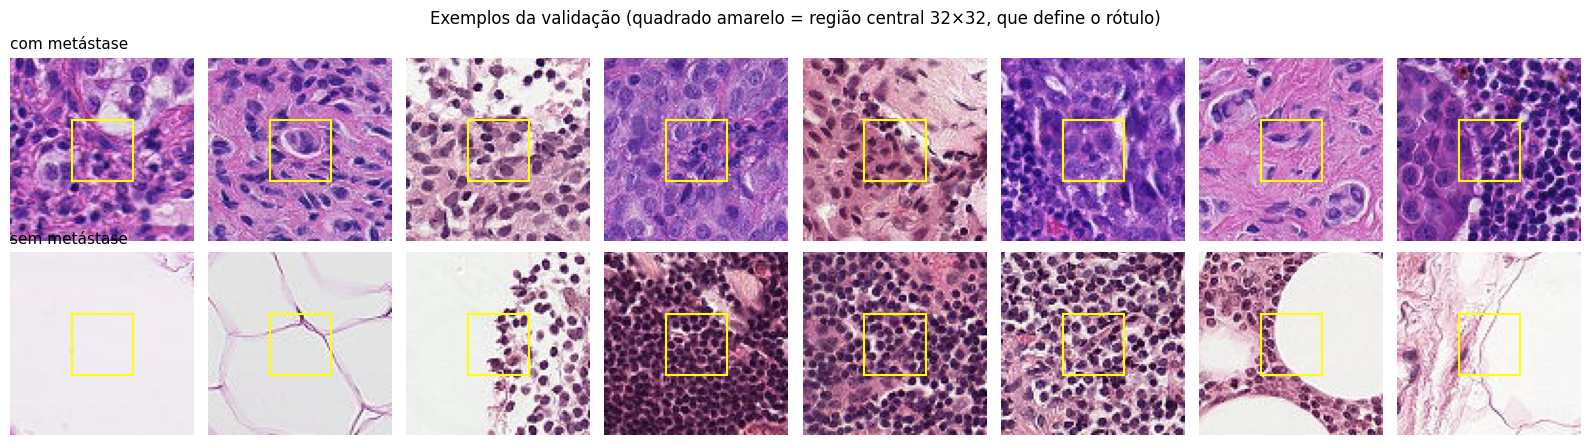

In [4]:
import io

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image


def abrir(imagem):
    """Converte a imagem guardada na base (bytes do PNG) em um objeto PIL."""
    return Image.open(io.BytesIO(imagem["bytes"]))


primeira = abrir(valid.loc[0, "image"])
print("Tamanho:", primeira.size, "| modo de cor:", primeira.mode)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for linha, rotulo in enumerate([True, False]):
    exemplos = valid[valid["label"] == rotulo].sample(8, random_state=42)
    for ax, (_, registro) in zip(axes[linha], exemplos.iterrows()):
        ax.imshow(abrir(registro["image"]))
        ax.add_patch(Rectangle((32, 32), 32, 32, fill=False, edgecolor="yellow", lw=1.5))
        ax.axis("off")
    axes[linha, 0].set_title("com metástase" if rotulo else "sem metástase", loc="left", fontsize=11)
fig.suptitle("Exemplos da validação (quadrado amarelo = região central 32×32, que define o rótulo)")
fig.tight_layout()
plt.show()

**Observações:**

- Formato confirmado: cada imagem está guardada como os bytes de um PNG (96 × 96, RGB); o rótulo é booleano.
- A base é **balanceada** (16.399 sem metástase, 16.369 com metástase na validação) — diferente de problemas como fraude, a acurácia não é enganosa aqui. A métrica principal será a **ROC AUC**.
- **Diferença visual:** com metástase, núcleos maiores, irregulares e espaçados; sem metástase, linfócitos pequenos e compactados, ou áreas brancas (gordura, fundo da lâmina).
- **Possível atalho:** muitas imagens negativas são quase todas brancas. Um modelo pode aprender "branco = negativo" sem reconhecer células — a ser verificado com Grad-CAM.
- **Variação de coloração** entre lâminas (de rosa-claro a roxo-escuro) — motiva aumento de dados com variação de cor, para que o modelo não dependa do tom.

## Download completo

Treino e teste. O **teste não será carregado** até o notebook final: só é baixado agora para que todos os dados fiquem no Drive.

In [5]:
snapshot_download(repo_id=REPO_HF, repo_type="dataset",
                  allow_patterns=["data/train-*", "data/test-*"], local_dir=DATA_DIR)

for split in ["train", "valid", "test"]:
    arquivos = sorted(DATA_DIR.rglob(f"{split}-*.parquet"))
    tamanho = sum(a.stat().st_size for a in arquivos) / 1e9
    print(f"{split:6s}: {len(arquivos):2d} arquivo(s), {tamanho:.2f} GB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

train : 13 arquivo(s), 6.12 GB
valid :  2 arquivo(s), 0.77 GB
test  :  2 arquivo(s), 0.75 GB
